In [9]:
import torch
import torchvision
import torchvision.transforms as transforms

batch_size = 128
img_size = 64
data_root = "/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/train"

train_dataset = torchvision.datasets.ImageFolder(
    root=data_root,
    transform=transforms.Compose([
        transforms.Grayscale(num_output_channels=1),
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
    ]))

# Read every image once and keep it in memory (training is much faster)
loader_once = torch.utils.data.DataLoader(train_dataset, batch_size=256, num_workers=2)
all_imgs = torch.cat([input for input, target in loader_once])
all_labels = torch.tensor(train_dataset.targets)

trainloader = torch.utils.data.DataLoader(
    torch.utils.data.TensorDataset(all_imgs, all_labels),
    batch_size=batch_size, shuffle=True)
print(all_imgs.shape)   # torch.Size([5216, 1, 64, 64])

torch.Size([5216, 1, 64, 64])


In [10]:
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Adapted from vanilla_vae by AntixK: https://github.com/AntixK/PyTorch-VAE/blob/master/models/vanilla_vae.py
# Also adapted from PyTorch example VAE: https://github.com/pytorch/examples/blob/main/vae/main.py
class VAE(nn.Module):
    def __init__(self, latent_dim=128, hidden_dims=None):
        super().__init__()
        if hidden_dims is None:
            hidden_dims = [32, 64, 128, 256]
        self.last_ch = hidden_dims[-1]

        modules = []
        in_ch = 1
        for h in hidden_dims:
            modules.append(nn.Sequential(
                nn.Conv2d(in_ch, h, kernel_size=4, stride=2, padding=1),
                nn.BatchNorm2d(h),
                nn.LeakyReLU(0.2)))
            in_ch = h
        self.encoder = nn.Sequential(*modules)
        self.fc_mu     = nn.Linear(self.last_ch * 4 * 4, latent_dim)
        self.fc_logvar = nn.Linear(self.last_ch * 4 * 4, latent_dim)

        self.fc_dec = nn.Linear(latent_dim, self.last_ch * 4 * 4)
        rev = hidden_dims[::-1]
        modules = []
        for i in range(len(rev) - 1):
            modules.append(nn.Sequential(
                nn.ConvTranspose2d(rev[i], rev[i + 1], kernel_size=4, stride=2, padding=1),
                nn.BatchNorm2d(rev[i + 1]),
                nn.ReLU()))
        self.decoder = nn.Sequential(*modules)
        self.final_layer = nn.Sequential(
            nn.ConvTranspose2d(rev[-1], 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid())

    def encode(self, x):
        h = self.encoder(x).flatten(start_dim=1)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        h = self.fc_dec(z).view(-1, self.last_ch, 4, 4)
        return self.final_layer(self.decoder(h))

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar


def vae_loss(recon, x, mu, logvar, beta=1.0):
    batch = x.size(0)
    recon_loss = F.binary_cross_entropy(recon, x, reduction="sum") / batch
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / batch
    return recon_loss + beta * kl_loss, recon_loss, kl_loss

In [11]:
def train_vae(beta, latent_dim, hidden_dims, lr, epochs=50, seed=0):
    torch.manual_seed(seed)
    m = VAE(latent_dim, hidden_dims).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    hist = {"total": [], "recon": [], "kl": []}
    for epoch in range(1, epochs + 1):
        m.train()
        sums = {"total": 0.0, "recon": 0.0, "kl": 0.0}; n = 0
        for x, _ in trainloader:
            x = x.to(device)
            opt.zero_grad()
            recon, mu, logvar = m(x)
            loss, rl, kl = vae_loss(recon, x, mu, logvar, beta=beta)
            loss.backward(); opt.step()
            sums["total"] += loss.item(); sums["recon"] += rl.item(); sums["kl"] += kl.item(); n += 1
        for k in sums:
            hist[k].append(sums[k] / n)
    return m, hist

In [12]:
!pip install -q pytorch-ignite
import ignite
print("ignite version:", ignite.__version__)

ignite version: 0.5.5


In [25]:
import logging
import ignite
import ignite.distributed as idist
from ignite.engine import Engine, Events
from torch.utils.data import TensorDataset
import PIL.Image as Image

ignite.utils.setup_logger(name="ignite.distributed.auto.auto_dataloader", level=logging.WARNING)
ignite.utils.setup_logger(name="ignite.distributed.launcher.Parallel", level=logging.WARNING)


class Generator(nn.Module):
    def __init__(self, vae):
        super().__init__()
        self.vae = vae

    def forward(self, noise):
        z = noise.view(noise.size(0), -1)      
        img = self.vae.decode(z)               
        return img.repeat(1, 3, 1, 1)          

g = torch.Generator().manual_seed(0)
eval_idx = torch.randperm(len(all_imgs), generator=g)[:3000]
test_dataset = TensorDataset(all_imgs[eval_idx].repeat(1, 3, 1, 1))

test_dataloader = idist.auto_dataloader(
    test_dataset,
    batch_size=batch_size,
    num_workers=2,
    shuffle=False,
    drop_last=True,
)

from ignite.metrics import FID, InceptionScore

fid_metric = FID(device=idist.device())

is_metric = InceptionScore(device=idist.device(), output_transform=lambda x: x[0])


def interpolate(batch):
    arr = []
    for img in batch:
        pil_img = transforms.ToPILImage()(img)
        resized_img = pil_img.resize((299,299), Image.BILINEAR)
        arr.append(transforms.ToTensor()(resized_img))
    return torch.stack(arr)


def evaluation_step(engine, batch):
    with torch.no_grad():
        noise = torch.randn(batch_size, latent_dim, 1, 1, device=idist.device())
        netG.eval()
        fake_batch = netG(noise)
        fake = interpolate(fake_batch)
        real = interpolate(batch[0])
        return fake, real


evaluator = Engine(evaluation_step)
fid_metric.attach(evaluator, "fid")
is_metric.attach(evaluator, "is")
print("evaluator ready, real images:", len(test_dataset), "->", len(test_dataloader), "batches")

evaluator ready, real images: 3000 -> 23 batches


In [ ]:
import time
import json
import pandas as pd


betas            = [0.1, 0.5, 1.0]
latent_dims      = [32, 128, 512]
hidden_dims_list = [[16, 32, 64, 128], [32, 64, 128, 256], [64, 128, 256, 512]]
lrs              = [1e-3, 1e-4]
EPOCHS = 50

results = []          
histories = {}        
n_total = len(betas) * len(latent_dims) * len(hidden_dims_list) * len(lrs)
run = 0
start_all = time.time()

for beta in betas:
    for latent_dim in latent_dims:                 
        for hidden_dims in hidden_dims_list:
            for lr in lrs:
                run += 1
                t0 = time.time()

                model, hist = train_vae(beta, latent_dim, hidden_dims, lr, epochs=EPOCHS)

                netG = Generator(model)
                ignite.utils.manual_seed(999)      
                evaluator.run(test_dataloader, max_epochs=1)
                metrics = evaluator.state.metrics
                fid_score = metrics['fid']
                is_score = metrics['is']

                name = f"b{beta}_z{latent_dim}_w{hidden_dims[0]}_lr{lr}"
                results.append({
                    "beta": beta, "latent_dim": latent_dim, "width": hidden_dims[0], "lr": lr,
                    "fid": fid_score, "is": is_score,
                    "final_recon": hist["recon"][-1], "final_kl": hist["kl"][-1],
                    "seconds": round(time.time() - t0, 1),
                })
                histories[name] = hist
                pd.DataFrame(results).to_csv("/kaggle/working/results.csv", index=False)
                with open("/kaggle/working/histories.json", "w") as f:
                    json.dump(histories, f)

                print(f"[{run:2d}/{n_total}] {name:<28} FID={fid_score:.4f}  IS={is_score:.3f}  "
                      f"({time.time() - t0:.0f}s, total {(time.time() - start_all) / 60:.1f} min)")

In [ ]:
df = pd.read_csv("/kaggle/working/results.csv")
print(df.sort_values("fid").to_string(index=False)) 

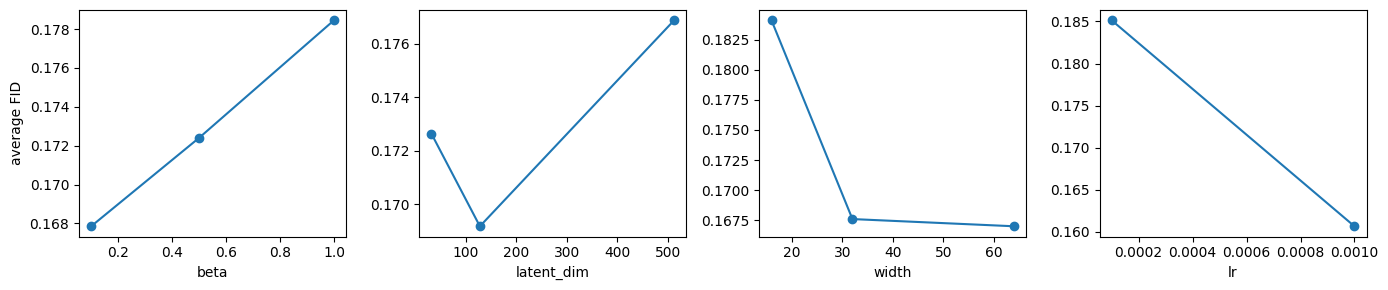

In [33]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(14, 3))
df.groupby("beta")["fid"].mean().plot(ax=axes[0], marker="o")
df.groupby("latent_dim")["fid"].mean().plot(ax=axes[1], marker="o")
df.groupby("width")["fid"].mean().plot(ax=axes[2], marker="o")
df.groupby("lr")["fid"].mean().plot(ax=axes[3], marker="o")
axes[0].set_ylabel("average FID")
plt.tight_layout(); plt.savefig("/kaggle/working/average_fid.png", dpi=200); plt.show()

In [29]:
beta = 0.1                            
latent_dim = 128                      
hidden_dims = [64, 128, 256, 512]     
lr = 1e-3                            

model, history = train_vae(beta, latent_dim, hidden_dims, lr, epochs=100)
torch.save(model.state_dict(), "/kaggle/working/vae_best.pt")

netG = Generator(model)
ignite.utils.manual_seed(999)
evaluator.run(test_dataloader, max_epochs=1)
metrics = evaluator.state.metrics
print("FID:", metrics['fid'], "  IS:", metrics['is'])

FID: 0.08436230904865086   IS: 1.6469402728233589


In [ ]:
from torchvision import utils
import matplotlib.pyplot as plt

def save_grid(imgs, nrow, title, path):
    grid = utils.make_grid(imgs, nrow=nrow, padding=2, pad_value=1.0)
    rows = imgs.size(0) // nrow
    plt.figure(figsize=(nrow * 1.2, rows * 1.2 + 0.6))
    plt.imshow(grid.permute(1, 2, 0)[:, :, 0], cmap="gray", vmin=0, vmax=1)
    plt.axis("off"); plt.title(title)
    plt.savefig(path, dpi=200, bbox_inches="tight"); plt.show()

ep = range(1, len(history["total"]) + 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, key, title in zip(axes, ["total", "recon", "kl"],
                          ["Total loss", "Reconstruction loss (BCE)", "KL divergence"]):
    # ax.plot(ep, history[key])
    ax.plot(list(ep)[1:], history[key][1:])
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.set_ylabel("Loss per image"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("/kaggle/working/loss_curves.png", dpi=200); plt.show()

model.eval()
with torch.no_grad():
    
    samples = model.decode(torch.randn(64, latent_dim, device=device)).cpu()
    save_grid(samples, 8, "Generated samples (z ~ N(0, I))", "/kaggle/working/generated.png")

    real = all_imgs[:8].to(device)
    mu, _ = model.encode(real)
    recon = model.decode(mu).cpu()
    save_grid(torch.cat([real.cpu(), recon]), 8, "Top: real   Bottom: reconstruction",
              "/kaggle/working/reconstruction.png")